In [1]:
import numpy as np, matplotlib.pyplot as plt
from dynesty_utils import simulate_data
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda
import fspiderman as sp
from hyperillumination_phasecurve_utils import *
from simple_bias_analysis import binned

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

A_B_true = 3/2 * 0.28 # 0.42 (Ag = 0.28 geometric albedo in the optical from Zieba 2022, placeholder)

# ASSUMPTION (!): Model for band-integrated albedo in MIRI/LRS band (MIR)
def A_model(A_B):
    # return A_B # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.
    return .1 # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR

# Filter to be used
instrument = "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

n_bins = 27 # number of bins in one orbit
sigma_1min      = 323. # detection error [ppm per minute], MIRI/LRS 5.0-10.5 um
n_orbits        = 3 # number of orbits observed (3 orbits has been done)

In [3]:
l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

# context for simulating data functions
cfg = FittingConfig(planet=K2_141b, stellar_grid=stellar_grid, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)

print(f"period = {K2_141b.period*24*60:.1f} min -> {n_bins} bins of {K2_141b.period*24*60/n_bins:.1f} min")
print(f"1-sigma per bin (over all orbits) = {cfg.sigma_bin:.1f} ppm")

no stellar models provided, using blackbody approximation
period = 403.7 min -> 27 bins of 15.0 min
1-sigma per bin (over all orbits) = 48.2 ppm


### 1. Simulated Data

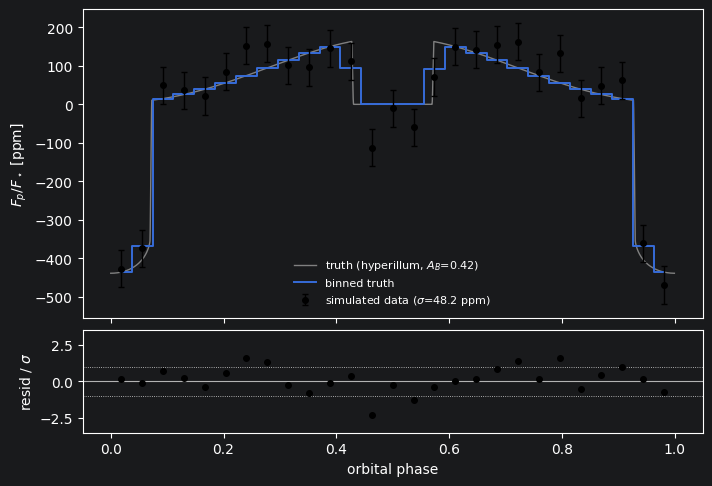

sigma_bin: 48.23 ppm  (bin width 14.95 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.76
residual mean / sigma (~0): 0.14


In [4]:
# Full Phase Curve (for custom reproduction of simulate_data)
t_hi, y_hi = model_pcurve(cfg, "hyperillum", A_B_true, n_t=200 * cfg.n_bins, n_layers=80, n_lo=600, n_la=300)
y_true = binned(cfg, y_hi)

# SIMULATED OBSERVATION
data = simulate_data(cfg, A_B_true=0.1, seed=0)
ph   = data["t"] / cfg.planet.period  # orbital phase
ph_hi = t_hi / cfg.planet.period

# Plotting
fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1], hspace=0.06))

ax.plot(ph_hi, y_hi, lw=1., color="0.5", label=f'truth (hyperillum, $A_B$={A_B_true:.2f})')
ax.step(ph, y_true, where="mid", color="C0", lw=1.4, label="binned truth")
ax.errorbar(ph, data["y_obs"], yerr=data["sigma"], fmt="o", ms=4, color="k", capsize=2,
            elinewidth=1., label=f'simulated data ($\\sigma$={cfg.sigma_bin:.1f} ppm)')
ax.set_ylabel("$F_p/F_\\star$ [ppm]"); ax.legend(frameon=False, fontsize=8); ax.margins(x=0.01)

r = (data["y_obs"] - y_true) / data["sigma"]
axr.axhline(0, color="0.7", lw=0.8); axr.axhline(1, color="0.85", lw=0.6, ls=":")
axr.axhline(-1, color="0.85", lw=0.6, ls=":")
axr.plot(ph, r, "ko", ms=4)
axr.set_xlabel("orbital phase"); axr.set_ylabel("resid / $\\sigma$"); axr.set_ylim(-3.5, 3.5)
plt.show()

# ── numerical checks ───────────────────────────────────────────────────────────────────────
chi2 = np.sum(r**2)
print(f"sigma_bin: {cfg.sigma_bin:.2f} ppm  (bin width {cfg.planet.period*24*60/cfg.n_bins:.2f} min)")
print(f"chi2 / n_bins (normalized average noise per bin ~1): {chi2/cfg.n_bins:.2f}")
print(f"residual mean / sigma (~0): {r.mean():.2f}")